##  Diplomado en Ciencia de Datos

<h1 align = 'center'> Solución: MLflow, autolog, modelos y registro </h1>

Soluciones de los ejercicios de `14_MLflow_Autolog_Modelos.ipynb`. El cuaderno es autocontenido: repite la configuración y resuelve cada ejercicio. Usa el nombre de modelo `clasificador_cancer_sol` para no chocar con el registro del cuaderno 14.

<h2 style="color: #007ACC;">Configuración (del cuaderno 14)</h2>

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn mlflow

In [2]:
import os, json, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import mlflow
from mlflow import MlflowClient
from mlflow.models import infer_signature

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve, ConfusionMatrixDisplay

os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'false'
mlflow.set_tracking_uri('sqlite:///mlflow_solucion.db')

datos = load_breast_cancer(as_frame=True)
X, y = datos.data, datos.target
SEMILLA = 42
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

modelo_final = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(X_tr, y_tr)
ejemplo = X_tr.head(3)
NOMBRE = 'clasificador_cancer_sol'
cliente = MlflowClient()

Para los ejercicios 3, 5 y 6 necesitamos un modelo guardado y registrado (el *champion* del cuaderno 14):

In [3]:
mlflow.set_experiment('sol-modelo-final');
with mlflow.start_run(run_name='regresion-logistica-final') as run_final:
    mlflow.log_params({'familia': 'Regresión logística', 'C': 1.0, 'semilla_particion': SEMILLA})
    info = mlflow.sklearn.log_model(modelo_final, name='modelo', signature=infer_signature(X_tr, modelo_final.predict_proba(X_tr)),
                                    input_example=ejemplo, pyfunc_predict_fn='predict_proba')
v1 = mlflow.register_model(info.model_uri, NOMBRE)
cliente.set_registered_model_alias(NOMBRE, 'champion', v1.version)
print('Versión', v1.version, 'con alias champion')

Versión 1 con alias champion


<h2 style="color: #007ACC;">Ejercicio 1. Autolog con GridSearchCV y un bosque aleatorio</h2>

In [4]:
mlflow.sklearn.autolog(log_models=False, log_datasets=False, max_tuning_runs=None, silent=True)
mlflow.set_experiment('sol-ej1-busqueda-rf');

cuadricula = {'n_estimators': [50, 200], 'max_depth': [2, 4, 8, None], 'min_samples_leaf': [1, 3, 10]}
busqueda = GridSearchCV(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1), cuadricula, cv=cv, scoring='average_precision')

with mlflow.start_run(run_name='GridSearch RF') as padre:
    busqueda.fit(X_tr, y_tr)

hijas = mlflow.search_runs(experiment_names=['sol-ej1-busqueda-rf'],
                           filter_string=f"tags.mlflow.parentRunId = '{padre.info.run_id}'")
hijas = hijas.rename(columns=lambda c: c.replace('params.', '').replace('metrics.', ''))
for c in cuadricula:
    hijas[c] = hijas[c].replace('None', np.nan).astype(float)
print(len(hijas), 'combinaciones')

24 combinaciones


Para saber **qué hiperparámetro tiene mayor efecto**, promediamos el puntaje de validación por cada valor de un hiperparámetro (marginalizando los demás) y miramos el rango que recorre:

In [5]:
efectos = {}
for c in cuadricula:
    marginal = hijas.assign(**{c: hijas[c].fillna(-1)}).groupby(c)['mean_test_score'].mean()
    efectos[c] = marginal.max() - marginal.min()
    print(f'{c:17s}', marginal.round(4).to_dict())
pd.Series(efectos).sort_values(ascending=False).round(4)

n_estimators      {50.0: 0.9885, 200.0: 0.9897}
max_depth         {-1.0: 0.9888, 2.0: 0.9874, 4.0: 0.9916, 8.0: 0.9886}
min_samples_leaf  {1.0: 0.9883, 3.0: 0.9887, 10.0: 0.9903}


max_depth           0.0043
min_samples_leaf    0.0021
n_estimators        0.0011
dtype: float64

**Respuesta.** El hiperparámetro con mayor recorrido es el que más mueve la PR-AUC de validación al cambiar su valor, promediando sobre los demás (aquí, `max_depth` (recorrido ≈ 0.004), seguido de `min_samples_leaf` (≈ 0.002) y, muy por detrás, `n_estimators` (≈ 0.001). Es un efecto **no monótono**: la profundidad 4 es la mejor, y tanto los árboles muy someros (2) como los muy profundos (8 o sin límite) rinden menos, lo que ilustra el equilibrio sesgo-varianza). Aun así, el efecto total es pequeño frente a la desviación entre pliegues: un indicio de que, en este problema, el ajuste fino no compensa. Un análisis más fino usaría la columna `std_test_score` para saber si las diferencias son significativas.

<h2 style="color: #007ACC;">Ejercicio 2. Registrar los datos con log_input</h2>

In [6]:
mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment('sol-ej2-datos');

with mlflow.start_run(run_name='regresion-logistica-con-datos') as r2:
    dataset = mlflow.data.from_pandas(X_tr.assign(objetivo=y_tr), targets='objetivo', name='cancer_train')
    mlflow.log_input(dataset, context='training')
    mlflow.log_input(mlflow.data.from_pandas(X_te.assign(objetivo=y_te), targets='objetivo', name='cancer_test'), context='testing')
    mlflow.log_params({'semilla_particion': SEMILLA})

entradas = mlflow.get_run(r2.info.run_id).inputs.dataset_inputs
for e in entradas:
    print(e.dataset.name, '| digest:', e.dataset.digest, '| contexto:', [t.value for t in e.tags if t.key == 'mlflow.data.context'])
print('Perfil:', json.loads(entradas[0].dataset.profile))

cancer_train | digest: facce0e9 | contexto: ['training']
cancer_test | digest: 6084f48b | contexto: ['testing']
Perfil: {'num_rows': 426, 'num_elements': 13206}


**Respuesta.** En la interfaz, la corrida muestra ahora una sección **Datasets used** con el nombre, el *contexto* (entrenamiento o prueba), la **huella digital** (`digest`, un hash del contenido) y el perfil (número de filas y columnas). Si alguien cambia el conjunto de datos sin cambiar su nombre, el `digest` cambia: es una forma barata de **detectar que dos corridas no usaron los mismos datos**.

<h2 style="color: #007ACC;">Ejercicio 3. Firma estricta</h2>

In [7]:
X_malo = X_te.head(3).astype({'mean radius': object}).copy()
X_malo['mean radius'] = ['grande', 'pequeño', 'mediano']

modelo_con_firma = mlflow.pyfunc.load_model(info.model_uri)
try:
    modelo_con_firma.predict(X_malo)
except Exception as e:
    print('CON firma  ->', type(e).__name__, ':', str(e).split('Error: ')[-1][:250])

CON firma  -> MlflowException : Incompatible input types for column mean radius. Can not safely convert str to float64.


Ahora guardamos el **mismo modelo sin firma** y repetimos:

In [8]:
with mlflow.start_run(run_name='sin-firma'):
    info_sf = mlflow.sklearn.log_model(modelo_final, name='modelo_sin_firma', pyfunc_predict_fn='predict_proba')
try:
    mlflow.pyfunc.load_model(info_sf.model_uri).predict(X_malo)
except Exception as e:
    print('SIN firma  ->', type(e).__name__, ':', str(e)[-200:])

SIN firma  -> ValueError : could not convert string to float: 'grande'


**Respuesta.** *Con* firma, MLflow detecta **antes de llamar al modelo** que `mean radius` debe ser `double` y falla con un mensaje que dice qué columna y qué tipo se esperaba. *Sin* firma, los datos llegan crudos al pipeline y el error (si lo hay) es el de scikit-learn, por ejemplo "could not convert string to float", que aparece muy adentro del escalador y sin decir qué columna del servicio original falló. Peor: si la columna mal formada fuera *convertible* (por ejemplo, un entero donde se espera decimal, o columnas en otro orden), sin firma el modelo respondería **en silencio con un resultado equivocado**. La firma convierte errores silenciosos en errores ruidosos.

<h2 style="color: #007ACC;">Ejercicio 4. Matriz de confusión con el umbral óptimo de validación</h2>

El umbral se elige **solo con el entrenamiento** (predicciones de validación cruzada, `cross_val_predict`); la prueba se usa únicamente para mostrar la matriz resultante.

Umbral óptimo en validación: 0.512 (F1 de validación = 0.9851)


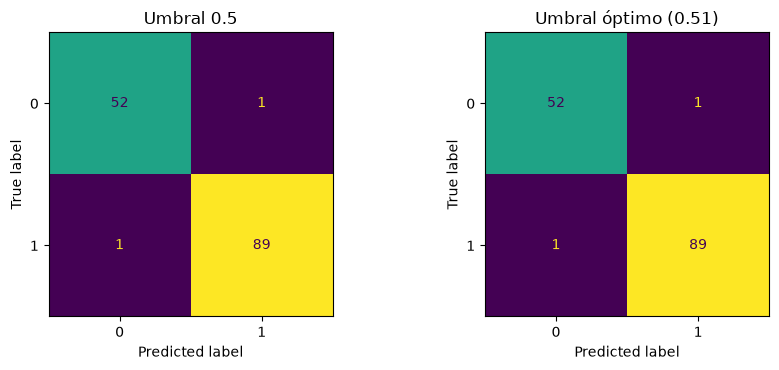

In [9]:
p_val = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)), X_tr, y_tr,
                          cv=cv, method='predict_proba')[:, 1]
precision, recall, umbrales = precision_recall_curve(y_tr, p_val)
f1s = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
u_opt = umbrales[np.argmax(f1s)]
print(f'Umbral óptimo en validación: {u_opt:.3f} (F1 de validación = {f1s.max():.4f})')

p_te = modelo_final.predict_proba(X_te)[:, 1]
pred_te = (p_te >= u_opt).astype(int)

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.8))
ConfusionMatrixDisplay.from_predictions(y_te, (p_te >= 0.5).astype(int), ax=ejes[0], colorbar=False); ejes[0].set_title('Umbral 0.5')
ConfusionMatrixDisplay.from_predictions(y_te, pred_te, ax=ejes[1], colorbar=False); ejes[1].set_title(f'Umbral óptimo ({u_opt:.2f})')
plt.tight_layout()

# Se añade a la corrida final con el cliente (funciona aunque el experimento activo sea otro)
cliente.log_param(run_final.info.run_id, 'umbral_optimo_validacion', round(float(u_opt), 4))
cliente.log_metric(run_final.info.run_id, 'test_f1_umbral_optimo', f1_score(y_te, pred_te))
cliente.log_figure(run_final.info.run_id, fig, 'matriz_confusion_umbral_optimo.png')

**Respuesta.** En este problema, casi separable, el umbral óptimo en validación es ≈ 0.51, muy cerca del 0.5 por defecto, así que las dos matrices son casi iguales; en un problema desbalanceado (cuaderno 12) la diferencia sería grande. Lo importante es el **procedimiento**: el umbral nace de predicciones fuera de muestra del entrenamiento (nunca de la prueba), se registra como parámetro de la corrida y la figura queda como artefacto.

<h2 style="color: #007ACC;">Ejercicio 5. Ciclo de vida: tercera versión y reversión</h2>

In [10]:
hgb = make_pipeline(StandardScaler(), HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, random_state=SEMILLA)).fit(X_tr, y_tr)

with mlflow.start_run(run_name='hist-gradient-boosting-candidato'):
    mlflow.set_tag('etapa', 'candidato')
    info3 = mlflow.sklearn.log_model(hgb, name='modelo', signature=infer_signature(X_tr, hgb.predict_proba(X_tr)),
                                     input_example=ejemplo, pyfunc_predict_fn='predict_proba',
                                     serialization_format='cloudpickle')
v3 = mlflow.register_model(info3.model_uri, NOMBRE)
cliente.set_registered_model_alias(NOMBRE, 'challenger', v3.version)

cv_champ = cross_validate(modelo_final, X_tr, y_tr, cv=cv, scoring='average_precision')['test_score']
cv_chal = cross_validate(hgb, X_tr, y_tr, cv=cv, scoring='average_precision')['test_score']
print(f'champion  (v{v1.version}): {cv_champ.mean():.4f} ± {cv_champ.std():.4f}')
print(f'challenger(v{v3.version}): {cv_chal.mean():.4f} ± {cv_chal.std():.4f}')

if cv_chal.mean() - cv_champ.mean() > cv_champ.std():
    cliente.set_registered_model_alias(NOMBRE, 'champion', v3.version); print('-> se promueve el challenger')
else:
    print('-> no se promueve: la diferencia no supera la variabilidad entre pliegues')

champion  (v1): 0.9974 ± 0.0029
challenger(v2): 0.9876 ± 0.0153
-> no se promueve: la diferencia no supera la variabilidad entre pliegues


Para **forzar** la promoción y practicar la **reversión**, movemos el alias a la versión 3 y luego de vuelta a la 1, comprobando en cada paso qué modelo recibe quien pide `@champion`:

In [11]:
def que_devuelve_champion():
    uri = f'models:/{NOMBRE}@champion'
    version = cliente.get_model_version_by_alias(NOMBRE, 'champion').version
    pred = mlflow.pyfunc.load_model(uri).predict(X_te.head(3))
    return version, np.round(pred[:, 1], 4).tolist()

print('Inicio              :', que_devuelve_champion())
cliente.set_registered_model_alias(NOMBRE, 'champion', v3.version)
print('Tras promover a v', v3.version, '   :', que_devuelve_champion())
cliente.set_registered_model_alias(NOMBRE, 'champion', v1.version)
print('Tras revertir a v', v1.version, '   :', que_devuelve_champion())

Inicio              : (1, [0.969, 0.0004, 0.5594])
Tras promover a v 2    : (2, [0.9819, 0.0042, 0.3843])
Tras revertir a v 1    : (1, [0.969, 0.0004, 0.5594])


**Respuesta.** (En este cuaderno el candidato queda como versión 2, porque aquí no registramos el bosque del cuaderno 14; el procedimiento es el mismo.) El código del consumidor (`models:/clasificador_cancer_sol@champion`) **no cambió** en ningún paso; solo se movió el alias. Con la reversión, las probabilidades vuelven a ser exactamente las de la versión 1. Eso es lo que hace barato el volver atrás: no hay que reentrenar ni redistribuir archivos.

Nota técnica: para el modelo de *boosting* se usó `serialization_format='cloudpickle'` en lugar del formato por defecto (`skops`), porque este último exige declarar uno a uno los tipos internos como confiables. `cloudpickle` es **menos seguro** (puede ejecutar código al cargarse): úsalo solo con modelos que tú mismo entrenaste.

<h2 style="color: #007ACC;">Ejercicio 6. Servir el modelo y compararlo con pyfunc</h2>

En una **terminal** (en la carpeta del cuaderno), con el mismo almacén de MLflow que usó este cuaderno:

```bash
export MLFLOW_TRACKING_URI=sqlite:///mlflow_solucion.db
mlflow models serve -m "models:/clasificador_cancer_sol@champion" -p 5001 --env-manager local
```

Con el servidor activo, esta celda consulta la API con `requests` y compara con `pyfunc` (si el servidor no está levantado, solo avisa):

In [12]:
import requests

cuerpo = {'dataframe_split': json.loads(X_te.head(5).to_json(orient='split'))}
local = mlflow.pyfunc.load_model(f'models:/{NOMBRE}@champion').predict(X_te.head(5))

try:
    r = requests.post('http://127.0.0.1:5001/invocations', json=cuerpo, timeout=10)
    r.raise_for_status()
    remoto = np.array(r.json()['predictions'])
    print('Coinciden exactamente:', np.array_equal(remoto, local))
    print('Diferencia máxima    :', np.abs(remoto - local).max())
except requests.exceptions.ConnectionError:
    print('El servidor no está levantado: ejecuta el comando de arriba en una terminal y repite esta celda.')

El servidor no está levantado: ejecuta el comando de arriba en una terminal y repite esta celda.


Y con `curl` (después de guardar el cuerpo en un archivo):

```bash
curl -s -X POST http://127.0.0.1:5001/invocations -H "Content-Type: application/json" -d @peticion.json
```

**Respuesta esperada.** (No se ejecutó en este cuaderno: requiere el servidor en una terminal aparte.) Las predicciones deben coincidir con `pyfunc` salvo diferencias numéricas mínimas por la conversión de los decimales a JSON, de modo que conviene comparar con `np.allclose` y no con igualdad exacta. Es el mismo modelo, el mismo preprocesamiento (porque guardamos el *pipeline* completo) y la misma firma; solo cambia el canal por el que llegan los datos.

<h2 style="color: #007ACC;">Ejercicio 7. Reflexión</h2>

**El problema.** Elegir el modelo con la `test_pr_auc` más alta entre 20 corridas es **seleccionar con el conjunto de prueba**. Con 20 candidatos, el mejor sobre la prueba está en parte ahí por azar (el máximo de 20 valores ruidosos está sesgado hacia arriba): la métrica reportada **sobreestima** el desempeño real, y la prueba deja de ser una estimación honesta porque participó en la decisión. Es el mismo mecanismo de fuga que vimos al ajustar hiperparámetros sobre la prueba.

**Cómo ayuda la estructura de este cuaderno.**

1. Los experimentos de **comparación** (`cancer-busqueda-svm`, `cancer-familias`) solo registran métricas de **validación cruzada** (`cv_*`, `mean_test_score`): nadie *puede* ordenarlos por prueba.
2. Las métricas `test_*` aparecen **una sola vez**, en el experimento `cancer-modelo-final`, en una corrida etiquetada `etapa=final`.
3. La decisión de promover un modelo (`challenger` → `champion`) se toma con validación y **queda registrada** en el Registry, con versión y alias.
4. Si alguien viola la regla, **el historial lo muestra**: 20 corridas con `test_*` es una señal visible en `search_runs`.

Una convención útil para un equipo: acordar prefijos (`cv_`, `val_`, `test_`) y revisar en cada revisión de código que las corridas de comparación no tengan `test_*`.